In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from optbinning import OptimalBinning
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='sklearn')
import cvxpy as cp

train_data = pd.read_csv("E:/credit_scorecard/data/train_processed.csv", low_memory=False)
test_data = pd.read_csv("E:/credit_scorecard/data/test_processed.csv", low_memory=False)
train_data.shape

(320354, 28)

In [3]:
train_data['default_flag'].value_counts(normalize=True)

default_flag
0    0.906794
1    0.093206
Name: proportion, dtype: float64

In [4]:
test_data['default_flag'].value_counts(normalize=True)

default_flag
0    0.906815
1    0.093185
Name: proportion, dtype: float64

In [2]:
# Separate numerical and categorical features
num_cols = train_data.drop(columns=['default_flag']).select_dtypes(include=[float,int]).columns.tolist()
cat_cols = train_data.drop(columns=['default_flag']).select_dtypes(exclude=[float,int]).columns.tolist()

#### __Identify Weak Variables__

In [3]:
# Store fitted OptBinning objects
optb_models = {}

# Store weak features
weak_cols = []

for col in train_data.drop(columns=['default_flag']).columns:

    # Determine variable type
    if col in num_cols:
        dtype = "numerical"
    else:
        dtype = "categorical"

    # OptBinning object
    optb = OptimalBinning(
        name=col,
        dtype=dtype,
        solver="mip",
    )

    # Fit using Train data only
    optb.fit(
        train_data[col].values,
        train_data["default_flag"].values
    )

    # Save the fitted OptBinning object
    optb_models[col] = optb

    # Build binning table
    binning_table = optb.binning_table.build()

    # Get IV
    iv_val = binning_table.loc["Totals", "IV"]

    # Identify weak variables
    if iv_val <= 0.015:
        weak_cols.append(col)

        print(f"{col}, Type: {dtype}, IV: {iv_val:.4f}")

emp_length, Type: numerical, IV: 0.0072
delinq_2yrs, Type: numerical, IV: 0.0005
mths_since_last_delinq, Type: numerical, IV: 0.0023
mths_since_last_record, Type: numerical, IV: 0.0020
open_acc, Type: numerical, IV: 0.0016
pub_rec, Type: numerical, IV: 0.0020
revol_bal, Type: numerical, IV: 0.0092
total_acc, Type: numerical, IV: 0.0095
total_rec_late_fee, Type: numerical, IV: 0.0000
collections_12_mths_ex_med, Type: numerical, IV: 0.0000
mths_since_last_major_derog, Type: numerical, IV: 0.0058


In [4]:
strong_cols = [col for col in train_data.drop(columns=['default_flag']).columns if col not in weak_cols]
print(strong_cols)

['term', 'int_rate', 'grade', 'home_ownership', 'verification_status', 'purpose', 'dti', 'inq_last_6mths', 'revol_util', 'initial_list_status', 'total_rec_int', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'loan_to_annl_inc', 'credit_history_length']


In [5]:
iv_vals = {col: optb_models[col].binning_table.build().loc["Totals", "IV"] for col in strong_cols}
iv_vals_sorted = pd.DataFrame.from_dict(iv_vals, orient='index', columns=['IV']).sort_values(by='IV', ascending=False) 
iv_vals_sorted

,IV
int_rate,0.344987
grade,0.271946
tot_cur_bal,0.092984
total_rev_hi_lim,0.090843
tot_coll_amt,0.064924
loan_to_annl_inc,0.064111
total_rec_int,0.052052
inq_last_6mths,0.049839
initial_list_status,0.043487
term,0.039327


In [6]:
# Drop the weak numerical variables 
train_data_sorted = train_data.loc[:,strong_cols + ['default_flag']]

#### __WoE transformed Train Data__

In [7]:
train_woe = train_data_sorted[['default_flag']].copy()

for col in strong_cols:
    optb = optb_models[col]
    woe_values = optb.transform(train_data_sorted[col].values, metric="woe")
    train_woe[f"{col}_woe"] = woe_values

print(f"Train WoE shape: {train_woe.shape}")

Train WoE shape: (320354, 17)


In [8]:
print(f"\nMissing values:\n{train_woe.isnull().sum()}")


Missing values:
default_flag                 0
term_woe                     0
int_rate_woe                 0
grade_woe                    0
home_ownership_woe           0
verification_status_woe      0
purpose_woe                  0
dti_woe                      0
inq_last_6mths_woe           0
revol_util_woe               0
initial_list_status_woe      0
total_rec_int_woe            0
tot_coll_amt_woe             0
tot_cur_bal_woe              0
total_rev_hi_lim_woe         0
loan_to_annl_inc_woe         0
credit_history_length_woe    0
dtype: int64


#### __Correlation Matrix__

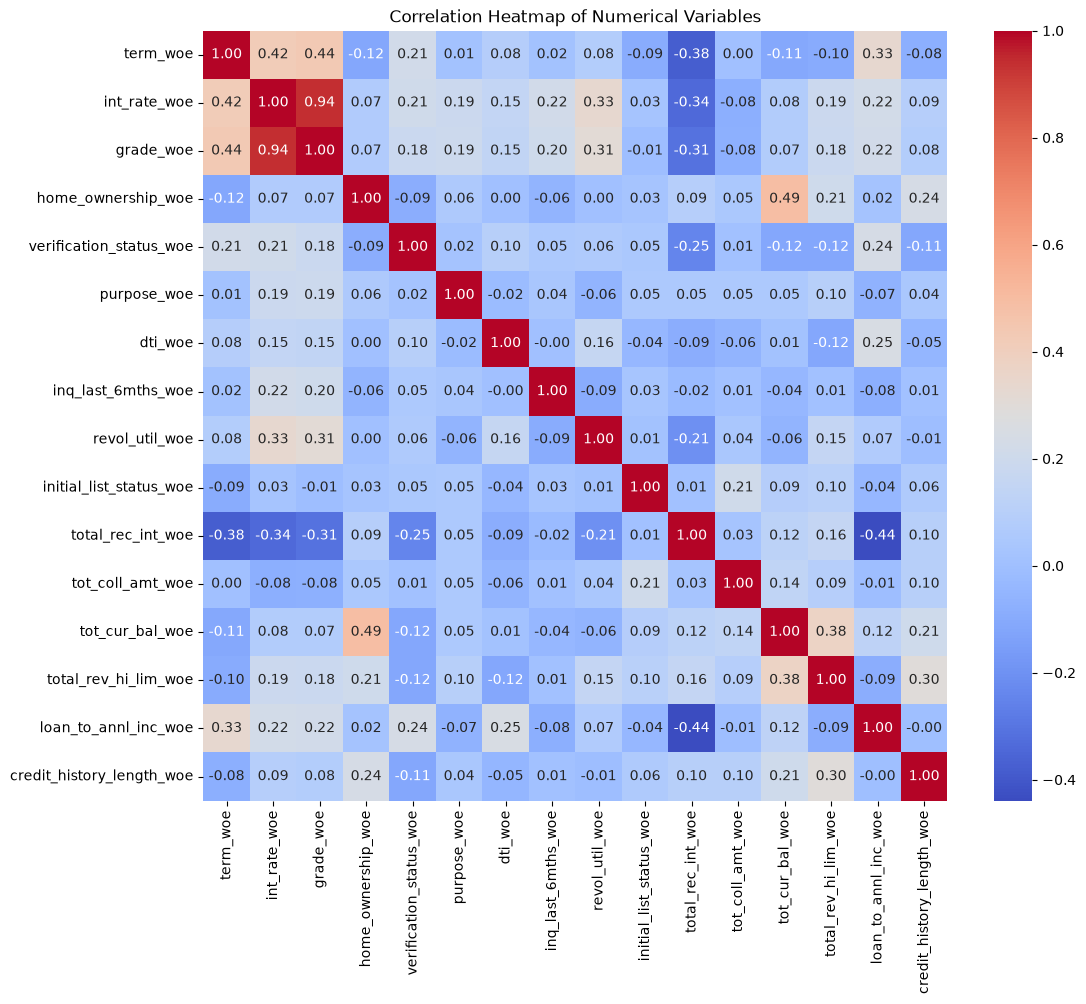

In [9]:
# We create a heatmap to observe the correlation between the numerical variables.
# Compute the correlation matrix 
num_cols = train_woe.drop(columns=['default_flag']).select_dtypes(include=[float,int]).columns.tolist()
corr_matrix = train_woe[num_cols].corr()

# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

In [10]:
mask = (corr_matrix.abs() > 0.70) & (corr_matrix.abs() < 1)
upper = corr_matrix.where(mask & np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))

res = upper.stack().dropna().reset_index()
res.columns = ['var1', 'var2', 'corr']
res

,var1,var2,corr
0,int_rate_woe,grade_woe,0.939928


#### __Variance Inflation Factor__

In [11]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train_woe = train_woe.drop(columns=['default_flag'])
y_train_woe = train_woe['default_flag']

def calc_vif(X):
    X = sm.add_constant(X)
    vif = pd.Series(
        [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
        index=X.columns
    )
    return vif.drop('const') 
calc_vif(X_train_woe)

term_woe                     1.511681
int_rate_woe                 9.345137
grade_woe                    8.932756
home_ownership_woe           1.375065
verification_status_woe      1.159460
purpose_woe                  1.094593
dti_woe                      1.132689
inq_last_6mths_woe           1.130675
revol_util_woe               1.306490
initial_list_status_woe      1.084214
total_rec_int_woe            1.532172
tot_coll_amt_woe             1.114225
tot_cur_bal_woe              1.619442
total_rev_hi_lim_woe         1.415871
loan_to_annl_inc_woe         1.497987
credit_history_length_woe    1.170770
dtype: float64

In [12]:
def drop_corr_cols(X, corr_threshold=0.7, vif_threshold=5):
    X = X.copy()
    dropped_cols = []

    while True:
        corr = X.corr().abs()
        mask = (corr > corr_threshold) & (corr < 1)
        mask = mask & np.triu(np.ones(corr.shape, dtype=bool), k=1)

        r, c = np.where(mask)
        if len(r) == 0:
            break

        pairs = sorted(
            zip(corr.index[r], corr.columns[c]),
            key=lambda p: corr.loc[p[0], p[1]],
            reverse=True,
        )

        vif = calc_vif(X)
        drop = None

        # first pair (strongest correlation) where the higher VIF exceeds the threshold
        for a, b in pairs:
            candidate = a if vif[a] >= vif[b] else b
            if vif[candidate] > vif_threshold:
                drop = candidate
                break

        if drop is None:   # all remaining correlated pairs have VIF <= threshold
            break

        dropped_cols.append(drop)
        X = X.drop(columns=[drop])

    return X, dropped_cols

X_train_clean, dropped = drop_corr_cols(X_train_woe)
print(f"Dropped because of multicollinearity: {dropped}")

Dropped because of multicollinearity: ['int_rate_woe']


#### __Optimal Threshold Checking__ 

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr = LogisticRegression(max_iter=1000, random_state=123)

# Out-of-fold predicted probabilities
oof_proba = np.zeros(len(X_train_clean))
for fold, (train_idx, val_idx) in enumerate(
    skf.split(X_train_clean, y_train_woe)
):
    X_tr = X_train_clean.iloc[train_idx]
    X_val = X_train_clean.iloc[val_idx]
    y_tr = y_train_woe.iloc[train_idx]

    lr.fit(X_tr, y_tr)
    oof_proba[val_idx] = lr.predict_proba(X_val)[:, 1]

y_true = y_train_woe.to_numpy()

# Calculate PR-AUC once using probabilities
pr_auc = average_precision_score(y_true, oof_proba)

# Recall across thresholds
thresholds = np.arange(0.10, 0.75, 0.05)
rows = []

for t in thresholds:
    y_pred = (oof_proba >= t).astype(int)

    rows.append({
        "threshold": round(t, 2),
        "recall": recall_score(y_true, y_pred)
    })

results = pd.DataFrame(rows)

print(f"OOF PR-AUC: {pr_auc:.6f}")
print(results.to_string(index=False))

OOF PR-AUC: 0.225020
 threshold   recall
      0.10 0.629057
      0.15 0.406444
      0.20 0.253893
      0.25 0.158076
      0.30 0.095214
      0.35 0.057202
      0.40 0.034295
      0.45 0.021367
      0.50 0.013162
      0.55 0.007904
      0.60 0.005158
      0.65 0.002780
      0.70 0.001440


#### __CV Variable Stability Test__

In [ ]:
# Define function for KS statistics
def ks_statistic(y_true, y_pred_proba):
    """Calculate KS statistic"""
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
    ks = np.max(tpr - fpr)
    return ks

def cv_stability_test(X, y, n_splits=10, random_state=560):
    """
    Cross-validation stability analysis:
    - AUC & KS model performance stability across K folds
    - Standard deviation of coefficients of variables across K folds 
    - Coefficient sign direction consistency across folds
    
    Args:
        X_woe: WOE transformed features (DataFrame)
        y: target variable
        n_splits: number of CV folds
    
    Returns:
        model_stability: Model-level metrics (AUC, KS)
        coef_stability: Variable-level coefficient stability
        coef_df: All fold coefficients
        signs_df: All fold coefficient signs
        metrics_dist: Detailed metric distributions
    """

    np.random.seed(random_state)
    n_samples = len(X)
    feature_names = X.columns.tolist()
    
    # Model-level metrics
    auc_train, auc_val = [], []
    ks_train, ks_val = [], []
    
    # Variable-level metrics
    coefficients, signs = [], []
    fold_indices = []
    
    # Stratified K-fold
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state) 

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_train = X.iloc[train_idx].reset_index(drop=True)
        y_train = y.iloc[train_idx].reset_index(drop=True)
        X_val = X.iloc[val_idx].reset_index(drop=True)
        y_val = y.iloc[val_idx].reset_index(drop=True)
        
        # Logistic Regression Model
        lr = LogisticRegression(max_iter=1000, random_state=random_state)
        lr.fit(X_train, y_train)
        
        # Predictions
        y_pred_train = lr.predict_proba(X_train)[:, 1]
        y_pred_val = lr.predict_proba(X_val)[:, 1]
        
        # AUC and KS Scores
        auc_train.append(roc_auc_score(y_train, y_pred_train))
        auc_val.append(roc_auc_score(y_val, y_pred_val))
        ks_train.append(ks_statistic(y_train, y_pred_train))
        ks_val.append(ks_statistic(y_val, y_pred_val))
        
        # Coefficient and Coefficient Signs 
        coef = lr.coef_[0]
        coefficients.append(coef)
        signs.append(np.sign(coef))
        fold_indices.append(fold)

    # Model Statbility Test 
    model_stability = pd.DataFrame({
        'Metric': ['AUC', 'KS'],
        'Train_Mean': [np.mean(auc_train), np.mean(ks_train)],
        'Train_Std': [np.std(auc_train), np.std(ks_train)],
        'Val_Mean': [np.mean(auc_val), np.mean(ks_val)],
        'Val_Std': [np.std(auc_val), np.std(ks_val)],
        'Train_CV': [np.std(auc_train) / np.mean(auc_train), 
                     np.std(ks_train) / np.mean(ks_train)],
        'Val_CV': [np.std(auc_val) / np.mean(auc_val), 
                   np.std(ks_val) / np.mean(ks_val)],
        'Overfit_Gap': [np.mean(auc_train) - np.mean(auc_val), 
                        np.mean(ks_train) - np.mean(ks_val)]
    }) 

    # Variable Statbility 
    coef_df = pd.DataFrame(coefficients, columns=feature_names)
    coef_df['Fold'] = fold_indices
    
    signs_df = pd.DataFrame(signs, columns=feature_names)
    signs_df['Fold'] = fold_indices
    
    coef_stability_results = []
    for var in feature_names:
        # Coefficient variation
        mean_coef = coef_df[var].mean()
        std_coef = coef_df[var].std()
        cv = std_coef / np.abs(mean_coef) if mean_coef != 0 else np.inf
        
        # Sign direction consistency
        var_signs = signs_df[var].values
        dominant_sign = np.sign(mean_coef)
        
        consistent_count = np.sum(var_signs == dominant_sign)
        consistency_pct = (consistent_count / len(var_signs)) * 100
        
        sign_flips = np.sum(var_signs == 0) + np.sum(var_signs != dominant_sign)
        flip_pct = (sign_flips / len(var_signs)) * 100
        
        # Stability flags
        cv_flag = 'PASS' if cv < 0.20 else 'FAIL'
        sign_flag = 'PASS' if consistency_pct >= 80 else 'FAIL'
        overall_flag = 'STABLE' if (cv_flag == 'PASS' and sign_flag == 'PASS') else 'UNSTABLE'
        
        coef_stability_results.append({
            'Variable': var,
            'Mean_Coef': mean_coef,
            'Std_Coef': std_coef,
            'CV': cv,
            'CV_Flag': cv_flag,
            'Dominant_Sign': '+' if dominant_sign > 0 else '-',
            'Sign_Consistency_%': consistency_pct,
            'Sign_Flip_%': flip_pct,
            'Sign_Flag': sign_flag,
            'Overall_Stability': overall_flag
        })
    
    coef_stability = pd.DataFrame(coef_stability_results).sort_values('Sign_Consistency_%', ascending=True)
    
    metrics_dist = {
        'auc_train': auc_train, 'auc_val': auc_val,
        'ks_train': ks_train, 'ks_val': ks_val
    }
    
    return model_stability, coef_stability, coef_df, signs_df, metrics_dist

model_stab, coef_stab, coef_df, signs_df, metrics_dist = cv_stability_test(X_train_clean,y_train_woe)

In [33]:
def print_cv_stability_report(model_stability, coef_stability):
    """Comprehensive Variable and Model Stability Analysis"""
    print("\n" + "="*100)
    print("Model Stability")
    print("="*100)
    print(model_stability.to_string(index=False))
    
    print("\n" + "="*100)
    print("Variable Stability")
    print("="*100)
    print(coef_stability.to_string(index=False))
    
    print("\n" + "="*100)
    print("Summary")
    print("="*100)
    print(f"AUC Stability (Val CV): {model_stability.loc[0, 'Val_CV']:.4f} {'✓ STABLE' if model_stability.loc[0, 'Val_CV'] < 0.05 else '✗ UNSTABLE'}")
    print(f"KS Stability (Val CV): {model_stability.loc[1, 'Val_CV']:.4f} {'✓ STABLE' if model_stability.loc[1, 'Val_CV'] < 0.10 else '✗ UNSTABLE'}")
    print(f"Overfitting (AUC Gap): {model_stability.loc[0, 'Overfit_Gap']:.4f} {'✓ LOW' if model_stability.loc[0, 'Overfit_Gap'] < 0.05 else '✗ HIGH'}")
    
    print(f"\nVariables with 100% sign consistency: {len(coef_stability[coef_stability['Sign_Consistency_%'] == 100])}")
    print(f"Variables with <80% sign consistency: {len(coef_stability[coef_stability['Sign_Consistency_%'] < 80])}")
    print(f"Stable variables (all criteria): {len(coef_stability[coef_stability['Overall_Stability'] == 'Stable'])}")
    print(f"Unstable variables (review needed): {len(coef_stability[coef_stability['Overall_Stability'] == 'Unstable'])}")

print_cv_stability_report(model_stab,coef_stab)


Model Stability
Metric  Train_Mean  Train_Std  Val_Mean  Val_Std  Train_CV   Val_CV  Overfit_Gap
   AUC    0.726210   0.000518  0.725984 0.004619  0.000714 0.006363     0.000226
    KS    0.330948   0.000516  0.332574 0.005557  0.001559 0.016709    -0.001625

Variable Stability
                 Variable  Mean_Coef  Std_Coef       CV CV_Flag Dominant_Sign  Sign_Consistency_%  Sign_Flip_% Sign_Flag Overall_Stability
                 term_woe  -0.454406  0.013073 0.028769    PASS             -               100.0          0.0      PASS            STABLE
                grade_woe  -0.927856  0.005905 0.006364    PASS             -               100.0          0.0      PASS            STABLE
       home_ownership_woe  -0.272870  0.017352 0.063591    PASS             -               100.0          0.0      PASS            STABLE
  verification_status_woe  -0.592757  0.019781 0.033371    PASS             -               100.0          0.0      PASS            STABLE
              purpose_woe

In [14]:
coef_stab.columns

Index(['Variable', 'Mean_Coef', 'Std_Coef', 'CV', 'CV_Flag', 'Dominant_Sign',
       'Sign_Consistency_%', 'Sign_Flip_%', 'Sign_Flag', 'Overall_Stability'],
      dtype='str')

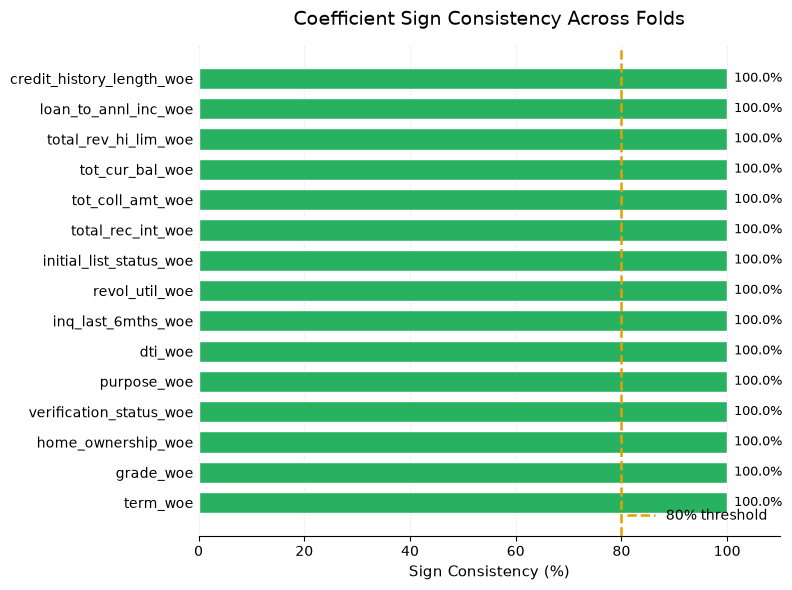

In [ ]:
# 1. Sign Consistency
plot_data = coef_stab.sort_values('Sign_Consistency_%')
fig, ax = plt.subplots(figsize=(8, 6))
colors = [
    "#8A3B3B" if x < 80 else "#28B161"
    for x in plot_data['Sign_Consistency_%']
]

bars = ax.barh(
    plot_data['Variable'],
    plot_data['Sign_Consistency_%'],
    color=colors,
    height=0.7,
    edgecolor='white'
)
# Threshold
ax.axvline(
    80,
    color='#E69F00',
    linestyle='--',
    linewidth=1.8,
    label='80% threshold',
    zorder=3
)
# Value labels
ax.bar_label(bars, fmt='%.1f%%', padding=5, fontsize=9)

# Formatting
ax.set_xlim(0, 110)
ax.set_xlabel('Sign Consistency (%)', fontsize=11)
ax.set_title(
    'Coefficient Sign Consistency Across Folds',
    fontsize=14,
    pad=15
)

ax.grid(axis='x', linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.show()

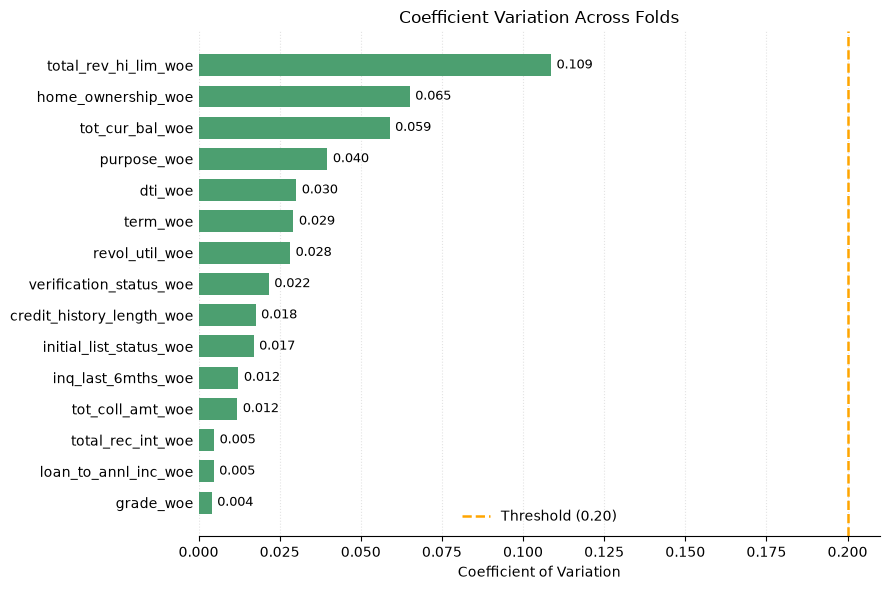

In [23]:

fig, ax = plt.subplots(figsize=(9, 6))
data = coef_stab.sort_values('CV')
colors = ['#D96C6C' if x > 0.20 else '#4C9F70'
          for x in data['CV']]

bars = ax.barh(data['Variable'], data['CV'],
               color=colors, height=0.7)

ax.axvline(0.20, color='orange', linestyle='--', linewidth=1.8,
           label='Threshold (0.20)')
ax.bar_label(bars, fmt='%.3f', padding=4, fontsize=9)
ax.set_xlabel('Coefficient of Variation')
ax.set_title('Coefficient Variation Across Folds')
ax.set_xlim(left=0)
ax.grid(axis='x', linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

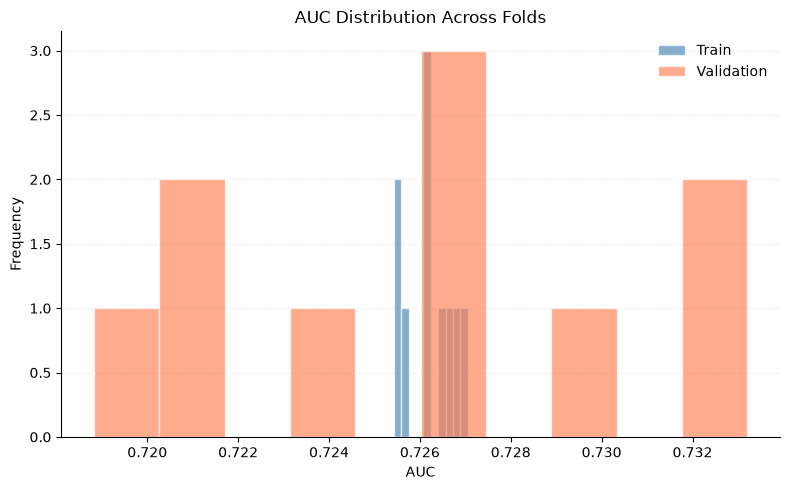

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(metrics_dist['auc_train'], bins=10, alpha=0.65,
        label='Train', color='steelblue', edgecolor='white')
ax.hist(metrics_dist['auc_val'], bins=10, alpha=0.65,
        label='Validation', color='coral', edgecolor='white')

ax.set_xlabel('AUC')
ax.set_ylabel('Frequency')
ax.set_title('AUC Distribution Across Folds')
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

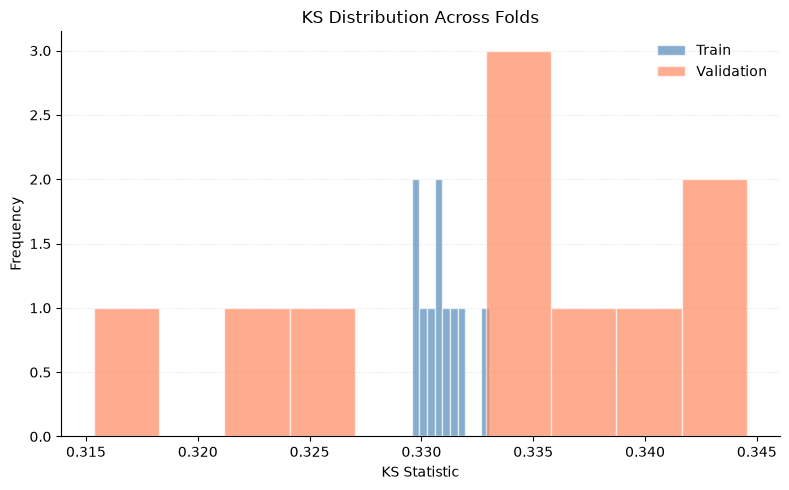

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(metrics_dist['ks_train'], bins=10, alpha=0.65,
        label='Train', color='steelblue', edgecolor='white')
ax.hist(metrics_dist['ks_val'], bins=10, alpha=0.65,
        label='Validation', color='coral', edgecolor='white')

ax.set_xlabel('KS Statistic')
ax.set_ylabel('Frequency')
ax.set_title('KS Distribution Across Folds')
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

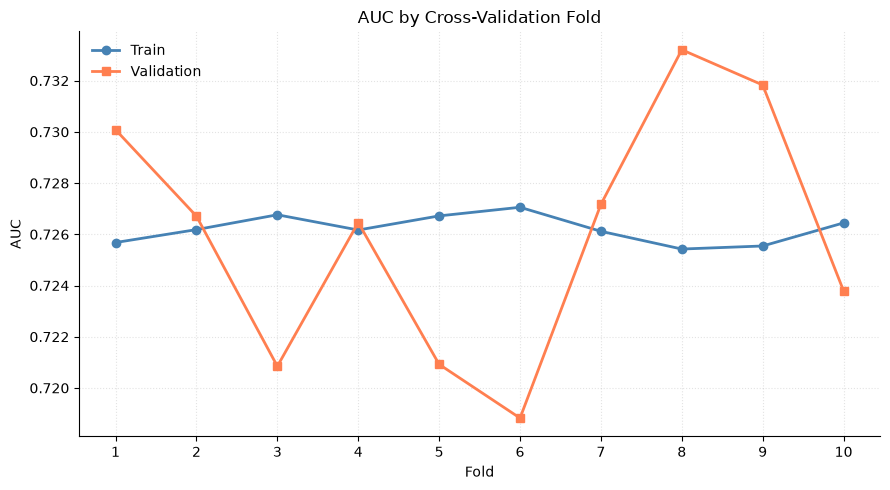

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))

folds = np.arange(1, len(metrics_dist['auc_train']) + 1)

ax.plot(folds, metrics_dist['auc_train'], 'o-',
        label='Train', linewidth=2, markersize=6, color='steelblue')
ax.plot(folds, metrics_dist['auc_val'], 's-',
        label='Validation', linewidth=2, markersize=6, color='coral')

ax.set_xticks(folds)
ax.set_xlabel('Fold')
ax.set_ylabel('AUC')
ax.set_title('AUC by Cross-Validation Fold')
ax.grid(linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

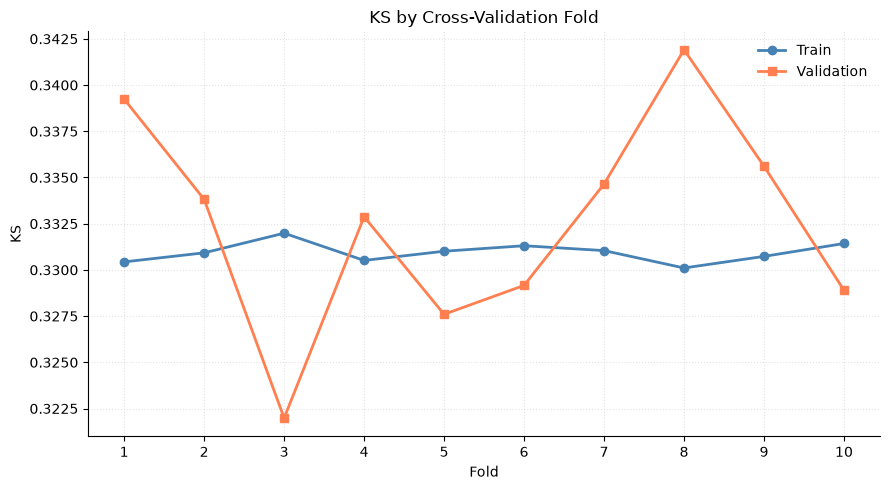

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))

folds = np.arange(1, len(metrics_dist['ks_train']) + 1)

ax.plot(folds, metrics_dist['ks_train'], 'o-',
        label='Train', linewidth=2, markersize=6, color='steelblue')
ax.plot(folds, metrics_dist['ks_val'], 's-',
        label='Validation', linewidth=2, markersize=6, color='coral')

ax.set_xticks(folds)
ax.set_xlabel('Fold')
ax.set_ylabel('KS')
ax.set_title('KS by Cross-Validation Fold')
ax.grid(linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

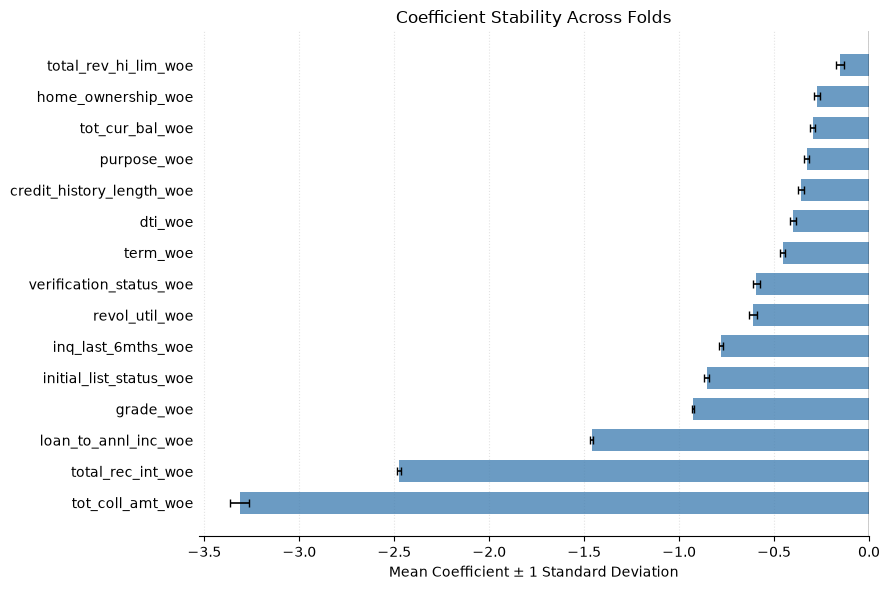

In [37]:
fig, ax = plt.subplots(figsize=(9, 6))

data = coef_stab.sort_values('Mean_Coef')

ax.barh(data['Variable'], data['Mean_Coef'],
        xerr=data['Std_Coef'], capsize=3,
        color='steelblue', alpha=0.8, height=0.7,
        error_kw={'elinewidth': 1.2})

ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Mean Coefficient ± 1 Standard Deviation')
ax.set_title('Coefficient Stability Across Folds')
ax.grid(axis='x', linestyle=':', alpha=0.35)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()